<a href="https://colab.research.google.com/github/curiousdatamind/utah-hospital-discharge-analysis/blob/main/Utah_Hospital_Discharge_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Instructions** #1: Find a Dataset--Locate a dataset online from a reputable source (e.g., Kaggle, data.gov, or an open API). Ensure the dataset is appropriate for analysis in terms of size, complexity, and relevance.

**Instructions** #2:Ingesting the Data--Import the data into Python. The method you use will depend on the format of the dataset (e.g., CSV, JSON, Excel, SQL database, API).

In [ ]:
import pandas as pd

df = pd.read_excel(
    "/content/sample_data/SH Excel Data For Colab Project.xlsx",
    header=0
)

df.head(10)

,Characteristic by Month,Jan-2017,Feb-2017,Mar-2017,Apr-2017,May-2017,Jun-2017,Jul-2017,Aug-2017,Sep-2017,...,Sep-2024,Oct-2024,Nov-2024,Dec-2024,Jan-2025,Feb-2025,Mar-2025,Apr-2025,May-2025,Jun-2025
0,Number of Discharges for the Month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,All discharges,23190,21838,24195,22872,23647,23372,22882,23280,22812,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Number of Discharges by Encounter Type,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Inpatient stays for normal newborns,2241,2158,2493,2461,2552,2620,2617,2464,2424,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Inpatient stays for deliveries,3625,3503,4046,4007,4144,4230,4240,4183,4096,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,"Non-elective inpatient stays, admitted through...",9265,8317,8782,8332,8635,8147,8268,8279,8118,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,"Non-elective inpatient stays, not admitted thr...",4348,4245,4737,4372,4509,4398,4265,4460,4511,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Elective inpatient stays,3711,3615,4137,3700,3807,3977,3492,3894,3663,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Number of Discharges by Priority Condition,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,COVID-19,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Instructions** #3: Data Cleaning--Perform data cleaning operations. Address missing values, incorrect data types, outliers, or duplicates as necessary. Document your cleaning steps with comments in your code.


Data Quality Observations — Current Findings
1. The dataset contains 134 rows and 103 columns.
2. Some rows are section headings rather than actual discharge observations.
3. All 134 rows contain at least one missing value.
4. All 102 monthly columns contain at least one missing value.
5. The monthly columns from January 2024 through June 2025 appear completely empty.
6. No completely duplicated rows were detected.
7. The dataset contains different types of hospital characteristics, so outlier analysis should compare values within the same characteristic over time rather than across unrelated categories.

Please reference the code that follows:

In [ ]:
# Examine the dataset
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Columns: 103 entries, Characteristic by Month to Jun-2025
dtypes: float64(18), object(85)
memory usage: 108.0+ KB


Data Quality Observations:

Observation # 1 — Structural missing values: The dataset contains section-heading rows with blank numeric cells. When imported into Pandas, these appear as NaN values. These rows organize the spreadsheet but are not actual discharge observations. They will need to be handled separately during data cleaning.

Here we can see that rows 0,2, and 8 are all sections headings, for example:

In [ ]:
# Missing values in rows
missing_by_row = df.isna().sum(axis=1)

print(missing_by_row.head(10))

0    102
1     18
2    102
3     18
4     18
5     18
6     18
7     18
8    102
9     57
dtype: int64


Observation #2: In addition to structural missing values associated with section headings, additional missing values are noted within rows containing actual data. For example, in Row 9, we note 57 missing values--in this case, it is likely because COVID19 related hospital discharges were not being measured in 2017.

Other missing values will likewise need to be accounted for.

Note:
int64 indicates that the missing value-counts are stored as integers

In [ ]:
df.columns[df.loc[1].isna()]

Index(['Jan-2024', 'Feb-2024', 'Mar-2024', 'Apr-2024', 'May-2024', 'Jun-2024',
       'Jul-2024', 'Aug-2024', 'Sep-2024', 'Oct-2024', 'Nov-2024', 'Dec-2024',
       'Jan-2025', 'Feb-2025', 'Mar-2025', 'Apr-2025', 'May-2025', 'Jun-2025'],
      dtype='object')

In [ ]:
df.loc[:, "Jan-2024":"Jun-2025"].count()

,0
Jan-2024,0
Feb-2024,0
Mar-2024,0
Apr-2024,0
May-2024,0
Jun-2024,0
Jul-2024,0
Aug-2024,0
Sep-2024,0
Oct-2024,0


Upon examining the code and the excel document, the missing 18 datapoints for rows 1, 3-7 can be accounted for.

The dataset includes monthly columns extending through June 2025. However, rows 1 and 3-7 respectively contain missing values for all 18 months from January 2024 through June 2025. This suggests that the available data for this measure ends in December 2023. Further inspection is needed to determine whether this pattern applies to other variables.

In [ ]:
# Missing values in every row
missing_by_row = df.isna().sum(axis=1)

print(missing_by_row)

0      102
1       18
2      102
3       18
4       18
      ... 
129     18
130     18
131     18
132     18
133    102
Length: 134, dtype: int64


In [ ]:
# Missing values in every column
missing_by_column = df.isna().sum(axis=0)

print(missing_by_column)

Characteristic by Month      0
Jan-2017                    20
Feb-2017                    20
Mar-2017                    20
Apr-2017                    20
                          ... 
Feb-2025                   134
Mar-2025                   134
Apr-2025                   134
May-2025                   134
Jun-2025                   134
Length: 103, dtype: int64


In [ ]:
# Rows with at least one missing value
df.isna().any(axis=1).sum()

np.int64(134)

In [ ]:
# Columns with at least one missing value
df.isna().any(axis=0).sum()

np.int64(102)

In [ ]:
encounters = df.loc[3:7, "Jan-2017":"Dec-2023"]

print(encounters.shape)

(5, 84)


In [ ]:
# Investigate duplicate values
duplicates = df.duplicated().sum()
print(duplicates)

0


In [ ]:
df.describe()

,Jan-2024,Feb-2024,Mar-2024,Apr-2024,May-2024,Jun-2024,Jul-2024,Aug-2024,Sep-2024,Oct-2024,Nov-2024,Dec-2024,Jan-2025,Feb-2025,Mar-2025,Apr-2025,May-2025,Jun-2025
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df[["Jan-2017", "Feb-2017", "Mar-2017"]].describe()

,Jan-2017,Feb-2017,Mar-2017
count,114,114,114
unique,112,112,112
top,176,***,94
freq,2,3,2


Observation 3: Non-numeric values: Some monthly discharge columns were imported as text rather than numeric data. At least one cell contains ***, suggesting that some values may be suppressed. Initial conclusion is that this suppression serves a purpose toward protecting patient privacy, but these entries will need to be investigated and handled appropriately before calculating descriptive statistics.

**Instructions** #4: Data Manipulation--Manipulate the dataset to prepare it for analysis. Your manipulation should include at least two of the following operations:
Sorting, Filtering (e.g., subset data based on conditions), Grouping (e.g., by categorical variables), Merging (if using multiple datasets), Reshaping the data (e.g., pivoting, melting)

In [ ]:
# For future reference, code that I can use for
# descriptive statistics across rows

# Select encounter types for rows 3-7
# and reporting months for Jan2017 through Dec2023
encounter_values = df.iloc[3:8, 1:85].copy()

# Convert monthly values to numeric
encounters_values = encounters.apply(pd.to_numeric, errors="coerce")

# Calculate statistics across rows
encounter_stats = encounters_values.agg(
    ["count", "mean", "median", "std", "min", "max"],
    axis=1
)

print(encounter_stats.round(2))

   count     mean  median     std     min      max
3   84.0  2232.64  2242.0  202.17  1763.0   2637.0
4   84.0  3730.43  3710.0  278.77  3197.0   4240.0
5   84.0  8971.06  8972.0  692.96  6702.0  10616.0
6   84.0  4795.15  4776.0  303.84  4233.0   5512.0
7   84.0  2827.76  2701.5  584.64  1177.0   4137.0


In [ ]:
df.dtypes.value_counts()

,count
object,85
float64,18


In [ ]:
for i, value in enumerate(df.iloc[:, 0]):
    print(i, value)

0 Number of Discharges for the Month
1 All discharges
2 Number of Discharges by Encounter Type
3 Inpatient stays for normal newborns
4 Inpatient stays for deliveries
5 Non-elective inpatient stays, admitted through the ED
6 Non-elective inpatient stays, not admitted through the ED
7 Elective inpatient stays 
8 Number of Discharges by Priority Condition
9 COVID-19
10 Influenza
11 Other acute or viral respiratory infections
12 Number of Discharges by Age in Years at Admission
13 Ages 0-4
14 Ages 5-9
15 Ages 10-17
16 Ages 18-44
17 Ages 45-64
18 Ages 65-79
19 Ages 80+
20 Number of Discharges by Sex
21 Male
22 Female
23 Number of Discharges by Urban-Rural Location of Patient's Residence
24 Large metro
25 Medium and small metros
26 Nonmetro
27 Missing
28 Number of Discharges by Community Income
29 Quartile 1, lowest income
30 Quartile 2-3, middle income quartiles
31 Quartile 4, highest income
32 Missing
33 Number of Discharges by Expected Primary Payer
34 Medicare
35 Medicaid
36 Private insu

In [ ]:
# Select encounter names and monthly values
encounters = df.iloc[3:8, 0:85].copy()

encounters.head()

,Characteristic by Month,Jan-2017,Feb-2017,Mar-2017,Apr-2017,May-2017,Jun-2017,Jul-2017,Aug-2017,Sep-2017,...,Mar-2023,Apr-2023,May-2023,Jun-2023,Jul-2023,Aug-2023,Sep-2023,Oct-2023,Nov-2023,Dec-2023
3,Inpatient stays for normal newborns,2241,2158,2493,2461,2552,2620,2617,2464,2424,...,2281,2005,2108,2282,2246,2238,2187,2162,1978,1955
4,Inpatient stays for deliveries,3625,3503,4046,4007,4144,4230,4240,4183,4096,...,3712,3439,3512,3678,3700,3745,3611,3582,3276,3319
5,"Non-elective inpatient stays, admitted through...",9265,8317,8782,8332,8635,8147,8268,8279,8118,...,9998,9432,9883,9311,9350,9750,9314,9719,9385,10468
6,"Non-elective inpatient stays, not admitted thr...",4348,4245,4737,4372,4509,4398,4265,4460,4511,...,5214,4804,4990,4777,4798,5052,4761,4891,4640,4957
7,Elective inpatient stays,3711,3615,4137,3700,3807,3977,3492,3894,3663,...,2769,2527,2583,2581,2497,2647,2687,2654,2574,2771


In [ ]:
# Convert only the monthly columns to numeric
encounters = df.iloc[3:8, 0:85].copy()

encounters.iloc[:, 1:] = encounters.iloc[:, 1:].apply(
    pd.to_numeric, errors="coerce"
)

encounters.head()

,Characteristic by Month,Jan-2017,Feb-2017,Mar-2017,Apr-2017,May-2017,Jun-2017,Jul-2017,Aug-2017,Sep-2017,...,Mar-2023,Apr-2023,May-2023,Jun-2023,Jul-2023,Aug-2023,Sep-2023,Oct-2023,Nov-2023,Dec-2023
3,Inpatient stays for normal newborns,2241,2158,2493,2461,2552,2620,2617,2464,2424,...,2281,2005,2108,2282,2246,2238,2187,2162,1978,1955
4,Inpatient stays for deliveries,3625,3503,4046,4007,4144,4230,4240,4183,4096,...,3712,3439,3512,3678,3700,3745,3611,3582,3276,3319
5,"Non-elective inpatient stays, admitted through...",9265,8317,8782,8332,8635,8147,8268,8279,8118,...,9998,9432,9883,9311,9350,9750,9314,9719,9385,10468
6,"Non-elective inpatient stays, not admitted thr...",4348,4245,4737,4372,4509,4398,4265,4460,4511,...,5214,4804,4990,4777,4798,5052,4761,4891,4640,4957
7,Elective inpatient stays,3711,3615,4137,3700,3807,3977,3492,3894,3663,...,2769,2527,2583,2581,2497,2647,2687,2654,2574,2771


In [ ]:
# Melting data to reshape data
# converting data from wide format to long format

encounters_melted = pd.melt(
    encounters,
    id_vars="Characteristic by Month",
    var_name="Month",
    value_name="Discharges"
)

# Remove leading and trailing spaces from encounter names
encounters_melted["Characteristic by Month"] = (
    encounters_melted["Characteristic by Month"].str.strip()
)

encounters_melted.head(10)

,Characteristic by Month,Month,Discharges
0,Inpatient stays for normal newborns,Jan-2017,2241
1,Inpatient stays for deliveries,Jan-2017,3625
2,"Non-elective inpatient stays, admitted through...",Jan-2017,9265
3,"Non-elective inpatient stays, not admitted thr...",Jan-2017,4348
4,Elective inpatient stays,Jan-2017,3711
5,Inpatient stays for normal newborns,Feb-2017,2158
6,Inpatient stays for deliveries,Feb-2017,3503
7,"Non-elective inpatient stays, admitted through...",Feb-2017,8317
8,"Non-elective inpatient stays, not admitted thr...",Feb-2017,4245
9,Elective inpatient stays,Feb-2017,3615


In [ ]:
# Convert Month to datetime

encounters_melted["Month"] = pd.to_datetime(
    encounters_melted["Month"],
    format="%b-%Y"
)

encounters_melted.head()

,Characteristic by Month,Month,Discharges
0,Inpatient stays for normal newborns,2017-01-01,2241
1,Inpatient stays for deliveries,2017-01-01,3625
2,"Non-elective inpatient stays, admitted through...",2017-01-01,9265
3,"Non-elective inpatient stays, not admitted thr...",2017-01-01,4348
4,Elective inpatient stays,2017-01-01,3711


**Instructions** #5: Data Visualization--Create at least three visualizations that help explain the key insights of your dataset using either Matplotlib or Seaborn.
Ensure you choose appropriate chart types (e.g., scatter plots, bar charts, histograms, heatmaps). Customize your visualizations with titles, labels, legends, and formatting for clarity.

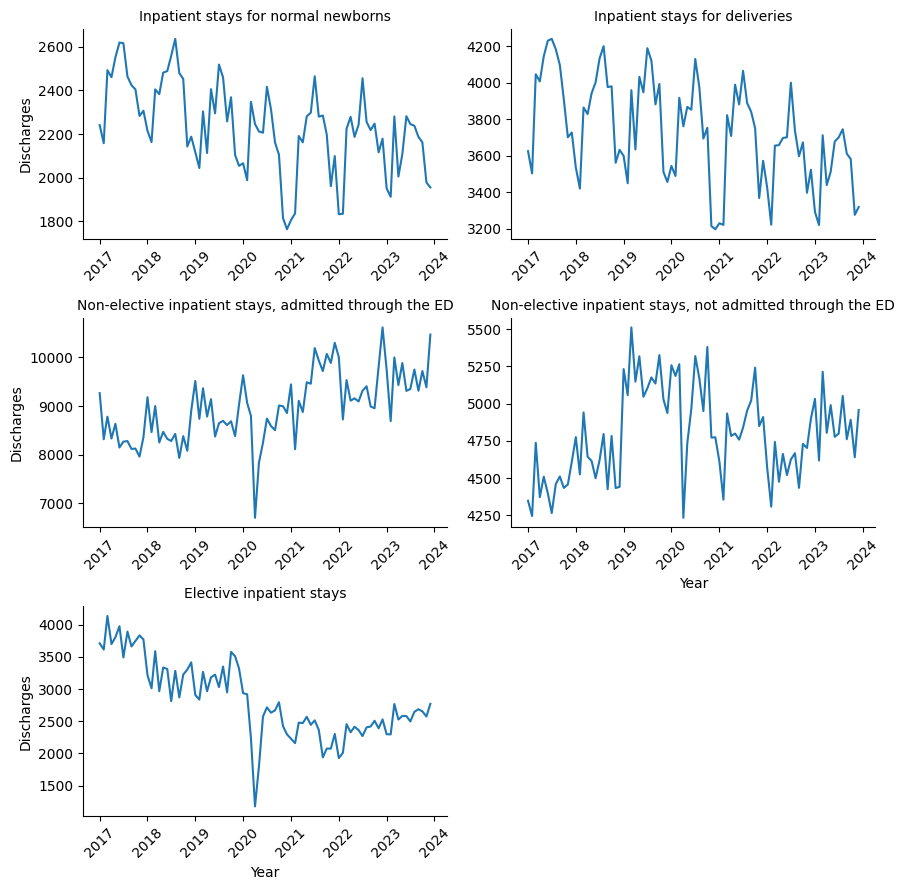

In [ ]:
# Small-multiple time-series graphs

import seaborn as sns
import matplotlib.pyplot as plt

g = sns.relplot(
    data=encounters_melted,
    x="Month",
    y="Discharges",
    col="Characteristic by Month",
    col_wrap=2,
    kind="line",
    height=3,
    aspect=1.5,
    facet_kws={"sharey": False}
)

g.set_titles("{col_name}")
g.set_axis_labels("Month", "Discharges")

for ax in g.axes.flat:
    ax.set_xlabel("Year")
    ax.tick_params(axis="x", labelbottom=True, rotation=45)

plt.tight_layout()
g.savefig("encounter_trends.png", dpi=300, bbox_inches="tight")
plt.show()

Hospital Discharge Trends By Encounter Type (2021-2023): The line graphs show different patterns in hospital discharges across five encounter types in Utah between 2017 and 2023.

Inpatient stays for normal newborns and deliveries show an overall downward trend, with the highest discharge counts generally occurring in 2017-2018 and particularly low values occurring around late 2020 to early 2021. Both categories exhibit recurring fluctuations throughout the study period, suggesting possible seasonal patterns.

Non-elective inpatient stays admitted through the emergency department (ED), non-elective stays not admitted through the ED, and elective inpatient stays all show sharp declines around early 2020. These declines coincide with the onset of the COVID-19 pandemic, suggesting a possible association with pandemic-related disruptions in healthcare utilization.

Following the initial decline, non-elective inpatient stays admitted through the ED generally increased, reaching higher discharge counts in 2022-2023 than in earlier years. Elective inpatient stays showed a partial recovery but remained below their 2017 levels. Non-elective inpatient stays not admitted through the ED fluctuated without a similarly clear sustained trend.

Overall, the visualizations suggest that hospital discharge patterns varied considerably by encounter type, with notable changes around 2020. However, these descriptive observations cannot establish that COVID-19 caused the changes. Additional analysis would be necessary to determine the effects of the pandemic, seasonal variation, demographic changes, and reporting practices.

Other notable observations: A noticeable increase in non-elective inpatient stays not admitted through the ED appears around January 2019, potentially associated with changes in reporting practices. Recovery patterns following the sharp declines in early 2020 differed across encounter types: ED-admitted non-elective stays generally increased, elective stays recovered only partially, and newborn and delivery discharges continued their overall downward trends. Newborn and delivery discharges also exhibited recurring fluctuations, suggesting possible seasonality, although further analysis would be needed to confirm this. Finally, each subplot uses a different y-axis scale, making trends within individual encounter types easier to observe but limiting direct visual comparisons of the magnitude of fluctuations between categories.

In [ ]:
# Age-group box plots

for i, value in enumerate(df.iloc[:, 0]):
    if "age" in str(value).lower():
        print(i, value)

12 Number of Discharges by Age in Years at Admission
13 Ages 0-4
14 Ages 5-9
15 Ages 10-17
16 Ages 18-44
17 Ages 45-64
18 Ages 65-79
19 Ages 80+
88 DIG004 Esophageal disorders                                                                                                        


In [ ]:
# Select age groups and monthly data (2017–2023)
ages = df.iloc[13:20, 0:85].copy()

# Convert discharge counts to numeric
ages.iloc[:, 1:] = ages.iloc[:, 1:].apply(
    pd.to_numeric, errors="coerce"
)

# Reshape from wide to long format
ages_melted = pd.melt(
    ages,
    id_vars="Characteristic by Month",
    var_name="Month",
    value_name="Discharges"
)

ages_melted.head()

,Characteristic by Month,Month,Discharges
0,Ages 0-4,Jan-2017,4921
1,Ages 5-9,Jan-2017,240
2,Ages 10-17,Jan-2017,549
3,Ages 18-44,Jan-2017,6890
4,Ages 45-64,Jan-2017,4340


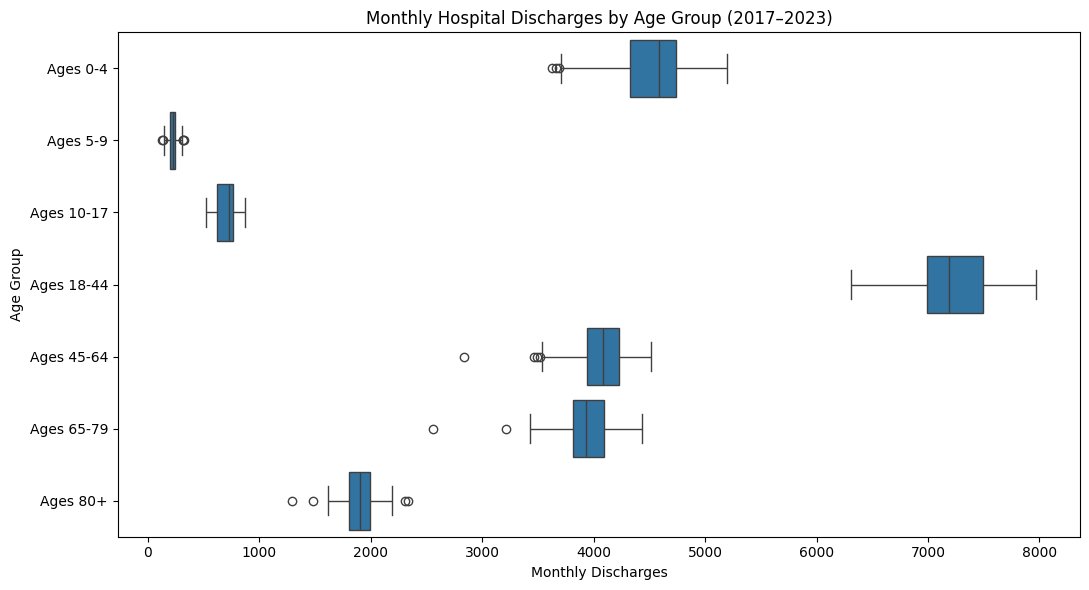

In [ ]:
# Horizontal box plots by age group
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=ages_melted,
    x="Discharges",
    y="Characteristic by Month"
)

plt.title("Monthly Hospital Discharges by Age Group (2017–2023)")
plt.xlabel("Monthly Discharges")
plt.ylabel("Age Group")

plt.tight_layout()
plt.savefig("age_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

Monthly Hospital Discharges by Age Group (2017-2023): The boxplots compare the distribution of monthly hospital discharges across seven age groups in Utah from 2017 to 2023.

Ages 18-44 had the highest median monthly discharge count (approximately 7,200), while ages 5-9 had the lowest (approximately 225). The 18-44 age group also exhibited a wider interquartile range (IQR), indicating greater absolute variability in monthly discharge counts compared with younger age groups.

Several age groups displayed unusually low discharge counts, represented by outliers below the lower whiskers. These observations may reflect disruptions in healthcare utilization, potentially including those associated with the COVID-19 pandemic. However, the boxplots do not identify when these outliers occurred or establish their causes.

An important limitation is that the age groups represent different age ranges and population sizes. Therefore, differences in total discharge counts should not be interpreted as differences in individual hospitalization risk. Population-adjusted rates would be necessary for that comparison.

Overall, the boxplots highlight differences in typical monthly discharge volumes and variability across age groups. The coefficient of variation (CV), examined in the next visualization, provides an additional measure for comparing relative variability between groups.

In [ ]:
# Calculate mean and coefficient of variation
# Mean is average monthly discharge count (sum of discharges/months)
# Coefficient of variation shows relative variability in groups
# (standard deviation/mean), expressed as percent

# Calculate statistics by age group
age_stats = ages_melted.groupby("Characteristic by Month")["Discharges"].agg(
    ["mean", "std"]
)

# Calculate coefficient of variation as a percentage
age_stats["CV"] = (
    age_stats["std"] / age_stats["mean"]
) * 100

age_stats = age_stats.reset_index()

age_stats.round(2)

,Characteristic by Month,mean,std,CV
0,Ages 0-4,4520.607143,325.42,7.198599
1,Ages 10-17,703.107143,92.18,13.109953
2,Ages 18-44,7215.559524,373.21,5.17233
3,Ages 45-64,4061.404762,269.15,6.626974
4,Ages 5-9,226.095238,41.84,18.504115
5,Ages 65-79,3933.809524,273.02,6.940329
6,Ages 80+,1896.464286,164.01,8.648367


Coefficient of Variation (CV) indicates how large the standard deviation is relative to the mean. It is notable that though the age group 18-44 has a much larger standard deviation in absolute numbers (373.21), relative to its mean, the standard deviation is notably smaller (5.17), indicating that ages 18-44 may have the highest average monthly discharge counts but the lowest relative variability.

Meanwhile, the age group 5-9 has the lowest average monthly discharge count but dmonstrates the highest relative variability.

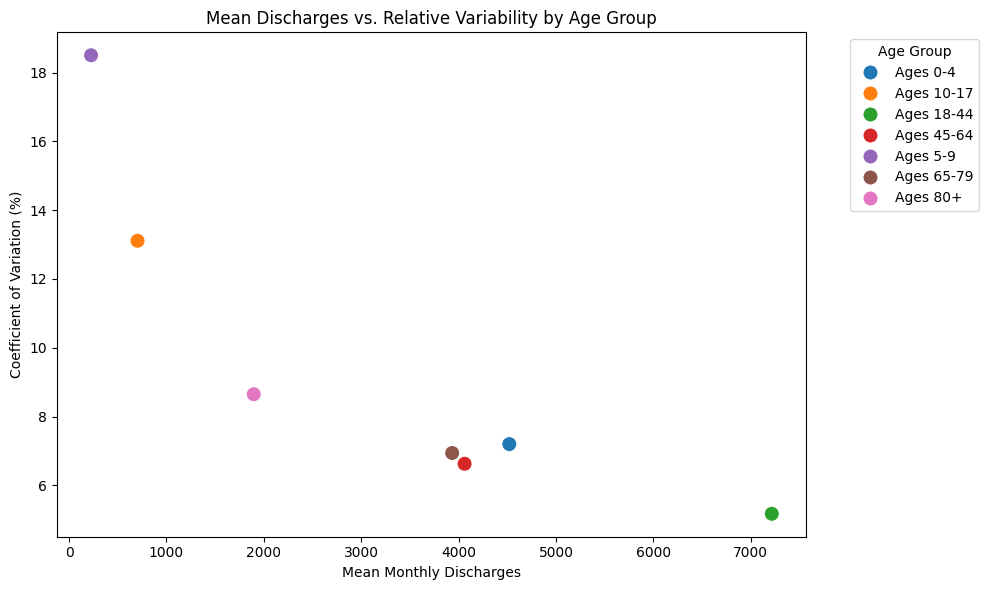

In [ ]:
# Scatterplot for discharges and age group

# Mean vs. coefficient of variation
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=age_stats,
    x="mean",
    y="CV",
    hue="Characteristic by Month",
    s=120
)

plt.title("Mean Discharges vs. Relative Variability by Age Group")
plt.xlabel("Mean Monthly Discharges")
plt.ylabel("Coefficient of Variation (%)")

plt.legend(title="Age Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("age_mean_cv.png", dpi=300, bbox_inches="tight")
plt.show()

Mean Monthly Discharges and Relative Variability by Age Group: The coefficient of variation (CV) measures the standard deviation relative to the mean, expressed as a percentage. This allows variability to be compared across age groups with substantially different average monthly discharge counts.

As discussed previously, although ages 18-44 have the largest absolute standard deviation (373.21 discharges), this group has the lowest relative variability (CV = 5.17%) because its mean monthly discharge count is much higher (7,215.56). In contrast, ages 5-9 have the lowest mean monthly discharge count (226.10) but the highest relative variability (CV = 18.50%).

The scatterplot suggests an inverse relationship between mean monthly discharge volume and relative variability: groups with lower average discharge counts generally have higher CV values. Ages 10-17 also demonstrate relatively high variability (13.11%), while most other age groups have CV values between approximately 5% and 9%.

These findings demonstrate that greater absolute variability does not necessarily indicate greater relative variability. However, CV can be more sensitive when mean values are small, and the observed relationship does not establish causation.

**Instructions** #6: Statistical Analysis--Conduct a statistical analysis on the dataset. This may involve:
Descriptive statistics (e.g., mean, median, mode, standard deviation), Correlation analysis, Distribution analysis

In [ ]:
# Descriptive Statistics

# Select encounter types for rows 3-7
# and reporting months for Jan2017 through Dec2023
encounter_values = df.iloc[3:8, 1:85].copy()

# Convert monthly values to numeric
encounters_values = encounters.apply(pd.to_numeric, errors="coerce")

# Calculate statistics across rows
encounter_stats = encounters_values.agg(
    ["count", "mean", "median", "std", "min", "max"],
    axis=1
)

print(encounter_stats.round(2))

   count     mean  median     std     min      max
3   84.0  2232.64  2242.0  202.17  1763.0   2637.0
4   84.0  3730.43  3710.0  278.77  3197.0   4240.0
5   84.0  8971.06  8972.0  692.96  6702.0  10616.0
6   84.0  4795.15  4776.0  303.84  4233.0   5512.0
7   84.0  2827.76  2701.5  584.64  1177.0   4137.0


In [ ]:
# Prepare data for Linear Regression

# Select two encounter types
regression_data = encounters_melted[
    encounters_melted["Characteristic by Month"].isin([
        "Elective inpatient stays",
        "Non-elective inpatient stays, admitted through the ED"
    ])
].copy()

# Create numeric time variable (months since January 2017)
regression_data["Time"] = (
    (regression_data["Month"].dt.year - 2017) * 12
    + regression_data["Month"].dt.month - 1
)

# Separate periods

# Create a new column for the regression periods
regression_data["Period"] = "Jan 2019 onward"

# Change the period for dates before January 2019
regression_data.loc[
    regression_data["Month"] < "2019-01-01",
    "Period"
] = "Before Jan 2019"

# Check the results
regression_data[["Month", "Time", "Period"]].head(30)


,Month,Time,Period
2,2017-01-01,0,Before Jan 2019
4,2017-01-01,0,Before Jan 2019
7,2017-02-01,1,Before Jan 2019
9,2017-02-01,1,Before Jan 2019
12,2017-03-01,2,Before Jan 2019
14,2017-03-01,2,Before Jan 2019
17,2017-04-01,3,Before Jan 2019
19,2017-04-01,3,Before Jan 2019
22,2017-05-01,4,Before Jan 2019
24,2017-05-01,4,Before Jan 2019


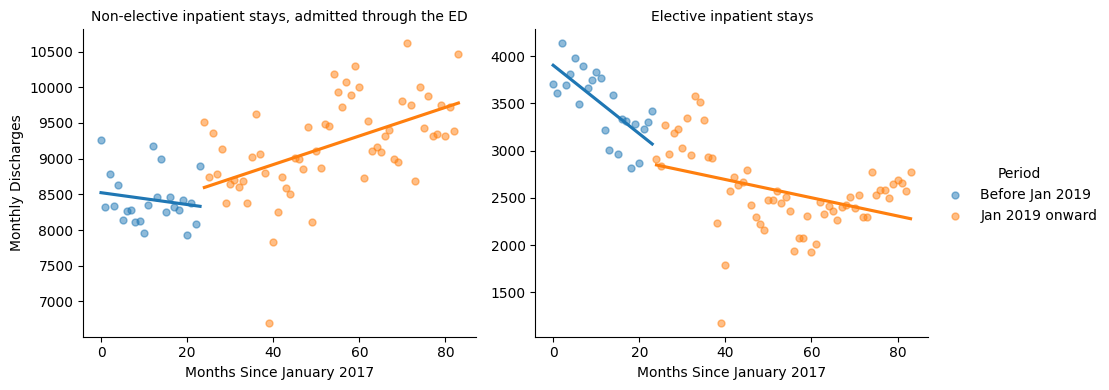

In [ ]:
# Create regression plots

# Linear regression by encounter type and period
g = sns.lmplot(
    data=regression_data,
    x="Time",
    y="Discharges",
    hue="Period",
    col="Characteristic by Month",
    col_wrap=2,
    height=4,
    aspect=1.2,
    scatter_kws={"alpha": 0.5, "s": 25},
    ci=None,
    facet_kws={"sharey": False}
)

g.set_axis_labels("Months Since January 2017", "Monthly Discharges")
g.set_titles("{col_name}")

g.savefig("regression_trends.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# To calculate regression statistics

regression_data.groupby(
    ["Characteristic by Month", "Period"]
)["Discharges"].count()



Characteristic by Month                                Period         
Elective inpatient stays                               Before Jan 2019    24
                                                       Jan 2019 onward    60
Non-elective inpatient stays, admitted through the ED  Before Jan 2019    24
                                                       Jan 2019 onward    60
Name: Discharges, dtype: int64

In [ ]:
# Calculate regression slopes

from scipy.stats import linregress

# Calculate regression statistics for each period
for (encounter, period), group in regression_data.groupby(
    ["Characteristic by Month", "Period"]
):

    # Ensure Time and Discharges are numeric
    x = pd.to_numeric(group["Time"], errors="coerce")
    y = pd.to_numeric(group["Discharges"], errors="coerce")

    # Remove rows with missing values
    valid = x.notna() & y.notna()
    x = x[valid]
    y = y[valid]

    # Calculate linear regression
    results = linregress(x, y)

    # Display results
    print(encounter)
    print(period)
    print("Slope:", round(results.slope, 2))
    print("R-squared:", round(results.rvalue**2, 3))
    print()

Elective inpatient stays
Before Jan 2019
Slope: -36.26
R-squared: 0.511

Elective inpatient stays
Jan 2019 onward
Slope: -9.65
R-squared: 0.155

Non-elective inpatient stays, admitted through the ED
Before Jan 2019
Slope: -8.3
R-squared: 0.027

Non-elective inpatient stays, admitted through the ED
Jan 2019 onward
Slope: 20.04
R-squared: 0.268



Linear Regression Analysis:

Linear regression was utilized to examine monthly hospital discharge trends for two encounter types: elective inpatient stays and non-elective inpatient stays admitted through the emergency department (ED). Separate regressions were calculated for periods before January 2019 and from January 2019 through December 2023.

Elective inpatient stays:

Before January 2019, elective inpatient stays exhibited a decreasing trend, with an estimated slope of -36.26 discharges per month (R² = 0.511). From January 2019 onward, the decline was less pronounced, with a slope of -9.65 discharges per month (R² = 0.155).

These results suggest that elective inpatient discharges declined during both periods, although the linear trend explained substantially more variation before January 2019.

Non-elective inpatient stays admitted through the ED:

Before January 2019, ED-related inpatient stays exhibited a slight downward trend, with a slope of -8.30 discharges per month (R² = 0.027). From January 2019 onward, the trend reversed, with an estimated increase of 20.04 discharges per month (R² = 0.268).

The low R² values indicate that linear time trends explained relatively little of the observed variation, particularly before January 2019.

Overall interpretation

The regression results reveal different patterns between elective and non-elective inpatient stays. Elective discharges declined across both periods, while non-elective ED admissions transitioned from a relatively weak downward trend to an upward trend.

These findings describe changes in hospital discharge patterns over time but do not establish their causes or whether the observed trends are statistically significant. Changes in reporting practices, healthcare utilization, and the COVID-19 pandemic may have influenced these patterns and warrant further investigation.

The explanatory value of time varied across encounter types and periods. Linear time trends accounted for approximately 51.1% of the variation in elective inpatient discharges before January 2019, compared with only 2.7% of the variation in non-elective ED admissions during the same period. These findings suggest that time was more strongly associated with discharge patterns in some categories than others. However, time itself should not be interpreted as a causal factor; changes in healthcare practices, patient populations, reporting methods, and other underlying conditions may contribute to the observed trends.

In [ ]:
# encounter categories included in regression analysis

regression_data["Characteristic by Month"].unique()

array(['Non-elective inpatient stays, admitted through the ED',
       'Elective inpatient stays'], dtype=object)